# Degree days from the daily grid, in two climates

This notebook goes from raw daily temperature on the 0.25 degree
NASA BCSD grid to heating and cooling degree days for impact regions
and provinces (GADM 2.0 ADM1), in Indonesia and Germany.

The same code runs on both. Indonesia should show cooling near 2,500
degree days at base 20 C and heating near zero; Germany the reverse.
Anything else is wrong on sight.

The sample is MRI-CGCM3, rcp85, 2020. The numbers are a
demonstration, not results.

In [1]:
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, TwoSlopeNorm

sys.path.insert(0, ".")
import compute

provinces = gpd.read_parquet(compute.PLOT_LAYER)
for iso, name in compute.COUNTRIES.items():
    print(f"{name}: {(provinces['ISO'] == iso).sum()} provinces")


def pair(figsize=(15, 4.5)):
    """Indonesia and Germany side by side, sized to their shapes."""
    return plt.subplots(1, 2, figsize=figsize,
                        gridspec_kw={"width_ratios": [2.4, 1]})

Indonesia: 33 provinces
Germany: 16 provinces


## The calendar

MRI-CGCM3 is on a Gregorian calendar, so 2020 has 366 days.
`read_bcsd_daily` drops Feb 29 by date and returns the 365-day year
the lab's products use.

In [2]:
for iso, name in compute.COUNTRIES.items():
    tasmax, _ = compute.read_year(iso)
    print(f"{name}: {compute.days_in_file('tasmax', iso)} days in the file, "
          f"{tasmax.values.shape[0]} returned")
print("around the end of February:", tasmax.dates[57:61])

Indonesia: 366 days in the file, 365 returned


Germany: 366 days in the file, 365 returned
around the end of February: ['2020-02-27' '2020-02-28' '2020-03-01' '2020-03-02']


## Degree days on the grid

The transform is the caller's: `compute.degree_days`, on the midpoint
of the daily extremes. It runs per cell per day, before aggregation;
degree days of an averaged temperature would be smaller. Each
variable has one colour scale across both countries.

4722 grid cells carry data


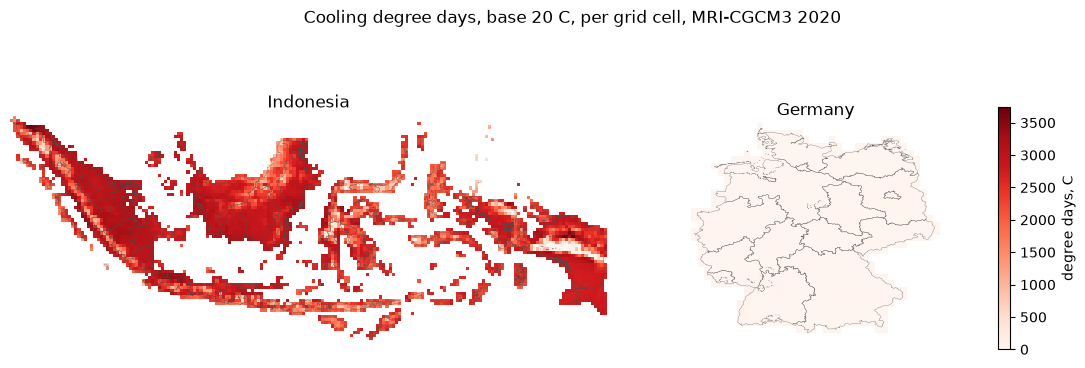

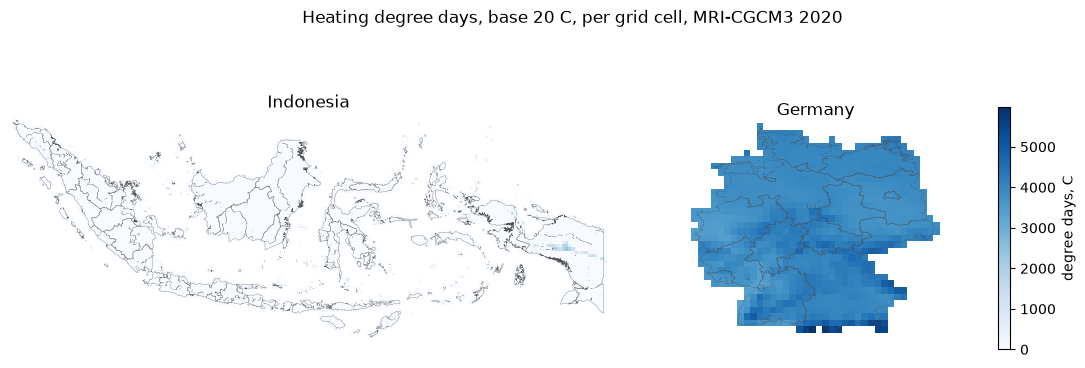

In [3]:
grids = {iso: compute.gridded(iso) for iso in compute.COUNTRIES}

for col, cmap, title in (("cdd", "Reds", "Cooling degree days"),
                         ("hdd", "Blues", "Heating degree days")):
    pick = 2 if col == "cdd" else 1
    vmax = max(np.nanmax(g[pick]) for g in grids.values())
    norm = Normalize(vmin=0.0, vmax=vmax)
    fig, axes = pair()
    for ax, (iso, g) in zip(axes, grids.items()):
        grid, field = g[0], g[pick]
        ax.pcolormesh(grid.lon, grid.lat, field, cmap=cmap, norm=norm,
                      shading="nearest")
        provinces[provinces["ISO"] == iso].boundary.plot(
            ax=ax, color="0.3", linewidth=0.2)
        ax.set_title(compute.COUNTRIES[iso])
        ax.set_aspect("equal")
        ax.set_axis_off()
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes,
                 shrink=0.7, label="degree days, C")
    fig.suptitle(f"{title}, base 20 C, per grid cell, "
                 f"{compute.MODEL} {compute.YEAR}")

cells = compute.all_cells()
print(len(cells), "grid cells carry data")

## Impact regions

The impact region weights come from an outside table: one row per
grid cell and impact region, shares already normalized, provenance
not recorded in the file. `from_table` reads it as is. There is no
shapefile here, so each region is drawn at the centre of its cells.

source coverage: 291 zero_weight source units (first 10: [[747, 573], [751, 576], [752, 575], [753, 577], [753, 580], [754, 576], [759, 549], [772, 551], [772, 552], [775, 577]]); recorded in the manifest and skipped


source coverage: 291 zero_weight source units (first 10: [[747, 573], [751, 576], [752, 575], [753, 577], [753, 580], [754, 576], [759, 549], [772, 551], [772, 552], [775, 577]]); recorded in the manifest and skipped


Indonesia: 442 impact regions
Germany: 200 impact regions


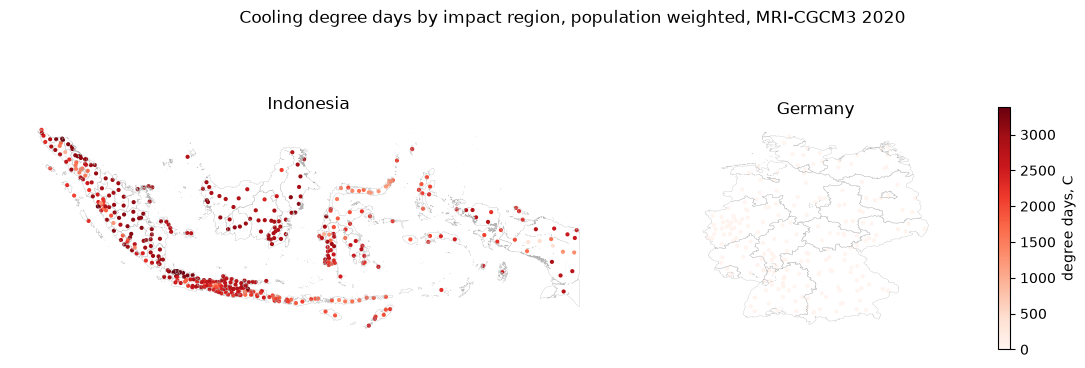

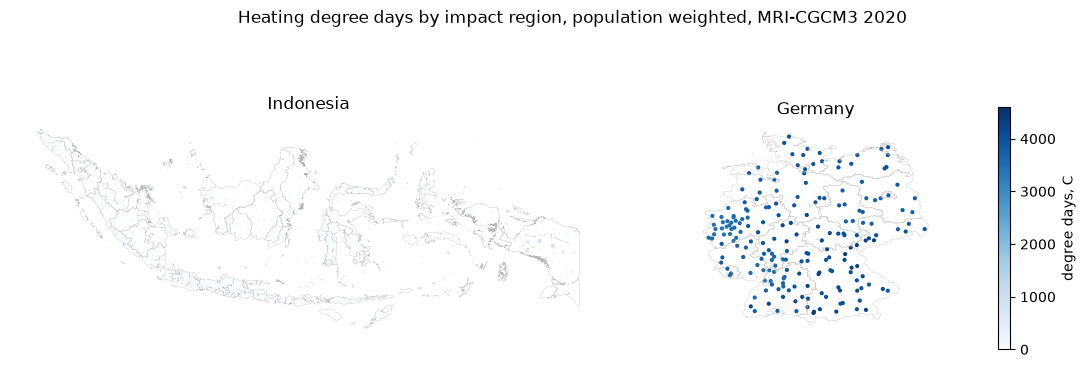

In [4]:
ir_weights = compute.load_ir_weights()
ir = compute.aggregate(ir_weights, cells, "pop").merge(
    compute.ir_locations(ir_weights), on="hierid")
for iso, name in compute.COUNTRIES.items():
    print(f"{name}: {(ir['ISO'] == iso).sum()} impact regions")

for col, cmap, title in (("cdd", "Reds", "Cooling degree days"),
                         ("hdd", "Blues", "Heating degree days")):
    norm = Normalize(vmin=0.0, vmax=float(ir[col].max()))
    fig, axes = pair()
    for ax, iso in zip(axes, compute.COUNTRIES):
        provinces[provinces["ISO"] == iso].boundary.plot(
            ax=ax, color="0.7", linewidth=0.2)
        s = ir[ir["ISO"] == iso]
        ax.scatter(s["lon"], s["lat"], c=s[col], cmap=cmap, norm=norm, s=4)
        ax.set_title(compute.COUNTRIES[iso])
        ax.set_aspect("equal")
        ax.set_axis_off()
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes,
                 shrink=0.7, label="degree days, C")
    fig.suptitle(f"{title} by impact region, population weighted, "
                 f"{compute.MODEL} {compute.YEAR}")

## Provinces

The province level uses the grid025 ADM1 weights. Zero-weight cells
are skipped explicitly (`compute.POLICIES`).

source coverage: 1 zero_weight source units (first 1: [[1189, 345]]); recorded in the manifest and skipped


source coverage: 1 zero_weight source units (first 1: [[1189, 345]]); recorded in the manifest and skipped


                                  heating  cooling
Indonesia, expected               about 0   ~2,500
Indonesia, population weighted          4    2,551
Indonesia, area weighted               16    2,446
Germany, expected                  ~3,700  about 0
Germany, population weighted        3,861       20
Germany, area weighted              3,983       15


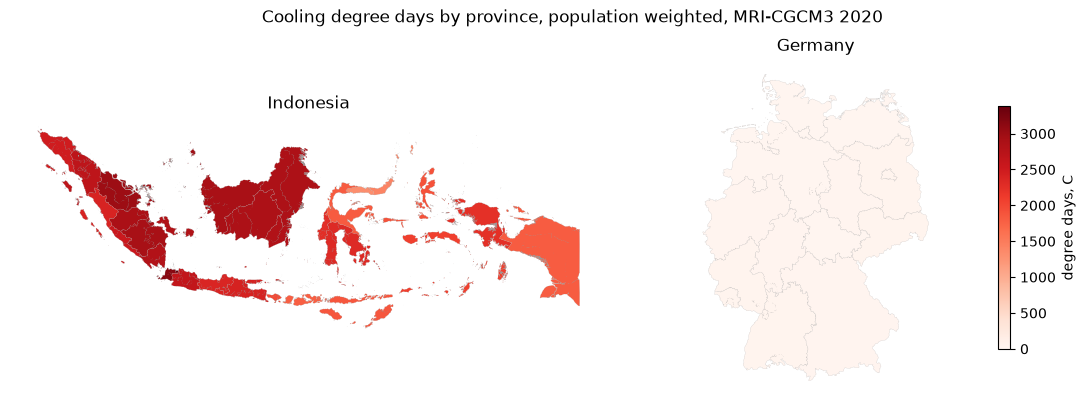

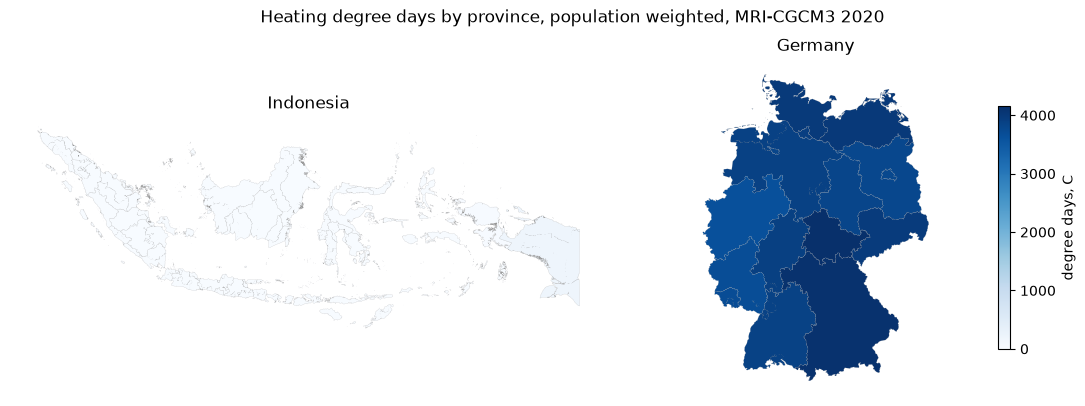

In [5]:
weights = compute.load_weights()
pop = compute.aggregate(weights, cells, "pop")
area = compute.aggregate(weights, cells, "area")
n_pop = compute.national(weights, pop, "pop")
n_area = compute.national(weights, area, "area")

print(f"{'':32s}{'heating':>9s}{'cooling':>9s}")
for iso, name in compute.COUNTRIES.items():
    e = compute.EXPECTED[iso]
    print(f"{name + ', expected':32s}{e['hdd']:>9s}{e['cdd']:>9s}")
    for label, n in (("population weighted", n_pop), ("area weighted", n_area)):
        print(f"{name + ', ' + label:32s}"
              f"{n.loc[iso, 'hdd']:9,.0f}{n.loc[iso, 'cdd']:9,.0f}")

m = provinces.merge(pop, on=compute.KEYS)
for col, cmap, title in (("cdd", "Reds", "Cooling degree days"),
                         ("hdd", "Blues", "Heating degree days")):
    norm = Normalize(vmin=0.0, vmax=float(m[col].max()))
    fig, axes = pair()
    for ax, iso in zip(axes, compute.COUNTRIES):
        m[m["ISO"] == iso].plot(column=col, ax=ax, cmap=cmap, norm=norm,
                                edgecolor="0.6", linewidth=0.1)
        ax.set_title(compute.COUNTRIES[iso])
        ax.set_axis_off()
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes,
                 shrink=0.7, label="degree days, C")
    fig.suptitle(f"{title} by province, population weighted, "
                 f"{compute.MODEL} {compute.YEAR}")

## Population against area weighting

Where people live warmer than the land around them, population
weighting raises cooling and lowers heating. The maps show each
country's dominant variable, population minus area.

Indonesia, cooling degree days, largest gaps:
          NAME_1  cdd_pop  cdd_area  cdd_diff
           Papua   1817.0    2308.0    -491.0
Kalimantan Timur   2856.0    2470.0     386.0
            Aceh   2491.0    2206.0     285.0
          Banten   3152.0    2894.0     257.0
Sulawesi Selatan   2312.0    2068.0     244.0 

Germany, heating degree days, largest gaps:
             NAME_1  hdd_pop  hdd_area  hdd_diff
             Hessen   3897.0    4060.0    -163.0
   Baden-Wrttemberg   3870.0    4030.0    -159.0
Nordrhein-Westfalen   3636.0    3788.0    -151.0
    Rheinland-Pfalz   3687.0    3791.0    -104.0
             Bayern   4113.0    4210.0     -97.0 



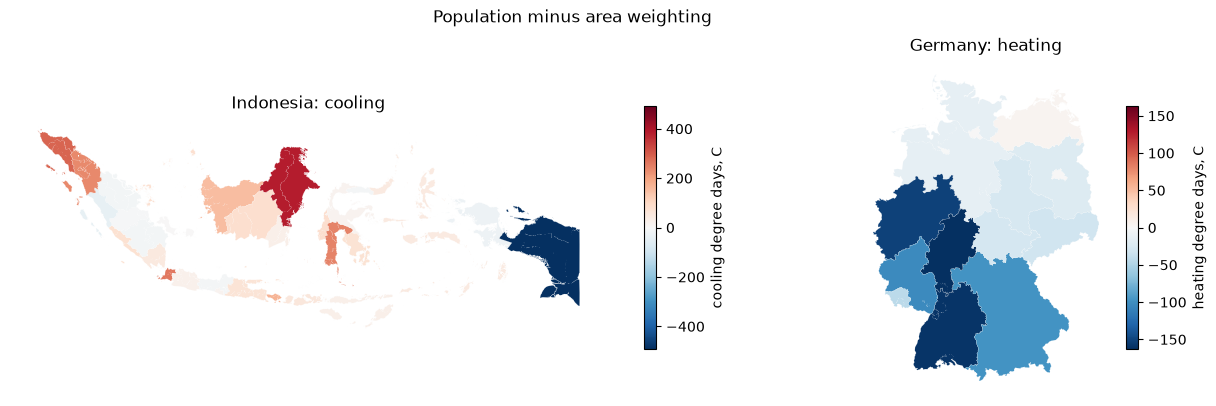

In [6]:
side = pop.merge(area, on=compute.KEYS, suffixes=("_pop", "_area"))
for col in ("hdd", "cdd"):
    side[f"{col}_diff"] = side[f"{col}_pop"] - side[f"{col}_area"]
d = provinces.merge(side, on=compute.KEYS)
dominant = {"IDN": ("cdd", "cooling"), "DEU": ("hdd", "heating")}

fig, axes = pair()
for ax, (iso, (col, label)) in zip(axes, dominant.items()):
    sub = d[d["ISO"] == iso]
    lim = float(np.abs(sub[f"{col}_diff"]).max())
    sub.plot(column=f"{col}_diff", ax=ax, cmap="RdBu_r",
             norm=TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim),
             edgecolor="white", linewidth=0.1, legend=True,
             legend_kwds={"label": f"{label} degree days, C", "shrink": 0.7})
    ax.set_title(f"{compute.COUNTRIES[iso]}: {label}")
    ax.set_axis_off()
fig.suptitle("Population minus area weighting")

for iso, (col, label) in dominant.items():
    sub = d[d["ISO"] == iso]
    sub = sub.reindex(sub[f"{col}_diff"].abs().sort_values(ascending=False).index)
    print(f"{compute.COUNTRIES[iso]}, {label} degree days, largest gaps:")
    print(sub.head(5)[["NAME_1", f"{col}_pop", f"{col}_area", f"{col}_diff"]]
          .round(0).to_string(index=False), "\n")

## The same weights, from a CSV

`adm1_weights.csv` is the province weights exported as a plain table
with centroid columns and no manifest. Read through `from_table`, it
must give the same numbers as the artifact.

In [7]:
from_csv = compute.load_weights_csv()
for label, w in (("population", "pop"), ("area", "area")):
    n, diff = compute.routes_agree(weights, from_csv, cells, w)
    print(f"{label} weights: artifact and from_table agree on {n} "
          f"provinces, largest difference {diff:.1e}")

source coverage: 1 zero_weight source units (first 1: [[1189, 345]]); recorded in the manifest and skipped


source coverage: 1 zero_weight source units (first 1: [[1189, 345]]); recorded in the manifest and skipped


source coverage: 1 zero_weight source units (first 1: [[1189, 345]]); recorded in the manifest and skipped


source coverage: 1 zero_weight source units (first 1: [[1189, 345]]); recorded in the manifest and skipped


population weights: artifact and from_table agree on 49 provinces, largest difference 0.0e+00
area weights: artifact and from_table agree on 49 provinces, largest difference 0.0e+00


## Your own weights or transform

For other weights, point `from_table` at the table, name the id and
weight columns, and give the grid in `source`. Keep centroid columns
if you have them; they let it check the cell indices.

For another transform, replace `compute.degree_days`, keep it per
cell per day, and aggregate afterwards. `DailyGrid.dates` gives the
dates for grouping by month.